# Polymorphism & Operator Overloading

**OOP notes on polymorphism.** "One name, many forms" — duck typing, letting
`+`, `>` and `print()` work on **your** objects by overloading Python's special (dunder)
methods like `__add__`, `__gt__` and `__str__`.

**What you will learn**
- What polymorphism means ("many faces")
- Duck typing: any object with the right method can be used
- Why `5 + "World"` fails and how `int.__add__` works behind `+`
- Overloading `+`, `>` and `print()` for your own classes with dunder methods

## Polymorphism — many faces, one action

- **Poly** = many, **morphism** = forms: the *same* operation behaves differently per object.
- `+` adds numbers but concatenates strings; `len()` measures lists, strings and dicts.
- Techniques: **duck typing** • **operator overloading** • **method overriding**.

Poly mean many and morphism means faces. 

Polymorphism is an object-oriented programming concept that refers to the ability of a variable, function or object to take on multiple forms.
A language that features polymorphism allows developers to program in the general rather than program in the specific.

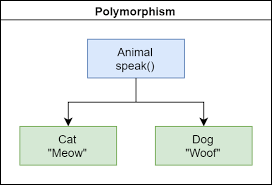

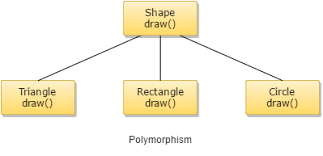

Ways to implement Polymorphism:
    
    -Duck Typing
    
    -Operator Overloading
    
    -Method Overloading
    
    -Method Overriding

## Polymorphism via duck typing

- "If it walks like a duck and quacks like a duck, it is a duck."
- Python does not check the *class* — it checks that the object **has the method you need**
  (here: `.execute()`), so PyCharm and Jupyter objects can be used interchangeably.

if it is a bird,which is walking like a duck,quaking like a duck, swimming like a duck then it is a duck
which mean it doesnt matter what is it, but if it is behaving like a duck then it is a duck

In [ ]:
# a name (label) can point to different objects — the value carries the type
x = 5
# x is just an identifier to the memory address that
#contain an int value 5

x = "Nasir"
# x is just an identifier to the memory address that
#contain an string value "Nasir"

There is no type of x but the type belongs to the value in the memory whose label is x.


In [ ]:
# duck typing: any object with execute() fits here, class identity is irrelevant
class PyCharm:   
    def execute(self):
        print("Compiling")
        print("Running")

class Jupyter:   
    def execute(self):
        print("Debugging")
        print("Posting")        

        print("Compiling")
        print("Running")        

        
class Laptop:
    def code(self,ide):
        ide.execute()
        
lap1 = Laptop() 
lap1.code(PyCharm())
lap1.code(Jupyter())

Now see its not important which class object your are passing, important is it must have a execute method.

If there is an object ide, it has an excecute method then definitely is an editor. 

## Polymorphism via operator overloading

- Operators are methods: `+` → `__add__`, `>` → `__gt__`, `print()` → `__str__`.
- `5 + 6` works because `int` defines `__add__`; `"Nasir" + "Hussain"` uses `str.__add__`.
- `5 + "World"` raises `TypeError` — int and str disagree about `+`.
- Our own classes need their **own** `__add__` before `s1 + s2` is allowed.

In [ ]:
# int.__add__ is what really runs behind the + operator
5 + 6 # here plus works as addition operator

In [ ]:
"Nasir" + "Hussain" # here plus is used as concatenation operator

In [ ]:
a =5 
b = "World"

a + b # error

> ⚠️ Expected `TypeError: unsupported operand type(s) for +: 'int' and 'str'` —
> Python has no rule that adds a number to text.

Why error? Coz everything is defined in Python.
We earlier said in Python everything is Object, it means int float string all are classes and when we assign integer it is actually integer object is created.

In [ ]:
# int.__add__(a, b) proves operators are just class methods
a =5
b= 8

print(a+b)
int.__add__(a,b)

In [ ]:
# help(int)

In [ ]:
# help(str)

In [ ]:
class Student:
    def __init__(self, m1, m2):
        self.m1 = m1
        self.m2 = m2 
s1 = Student(90,100)
s2 = Student(100,80)

s3 = s1 + s2 # error coz we have not defined if the tw oobjects of class student are added what to do??

In [ ]:
# we need to defined and add function in our class
# that will be called when two objects of our class will
# use  + operator

In [ ]:
# overload __add__ so + works on Student objects too
class Student:
    def __init__(self, maths, comp):
        self.maths = maths
        self.comp = comp 
        
    def __add__(self, other):# Student.__add__(s1,s2)
        maths = self.maths + other.maths
        comp = self.comp + other.comp
        s3 = Student(maths,comp)
        return s3        
        
s1 = Student(maths=90,comp=100)
s2 = Student(maths=100,comp=80)
s3 = s1+s2

In [ ]:
s3.maths

In [ ]:
s3.comp

---

## Extra practice: duck typing & operator overloading

## Polymorphism recap - practice drills

- The same two techniques again as extra exercises: duck typing and operator overloading.

#### Duck typing — behaviour beats class

- An object is accepted as long as it has the required method, e.g. `useLibrary()` or `execute()`.

If there a bird which is:
    - walking like a duck
    - which is quaking like a duck
    - which is swimming like a duck
          then it is a duck
          
Means its behaviour is just like a duck although it not a duck

In [ ]:
# same method name, different classes, one call site = polymorphism
class Student:
    def useLibrary(self):
        print("Reading Books")
        print("Making Notes")

s1 = Student()
################################
class Teacher:
    def useLibrary(self):
        print("Reading Books")
        print("Making Notes")
        print("Prepare Question Paper")

t1 = Teacher()
#####################################
class Library:
    def welcome(self, obj):
        obj.useLibrary()

        
lib  =Library()
        
lib.welcome(s1)
lib.welcome(t1)        

#### Another example — interchangeable IDEs

- `PyCharm` and `Jupyter` objects both expose `execute()`, so any function can call either.

In [ ]:
class PyCharm:
    def execute(self):
        print("Compiling")
        print("Running")
ide1 = PyCharm()

#################


class VsCode:
    def execute(self):
        print("Grammar Checking")
        print("Spell checking")
        print("Compiling")
        print("Running")
ide2 = VsCode()
#############################

class Laptop:
    def code(self,ide):
        ide.execute()
        
lap1 = Laptop()
lap1.code(ide1)
lap1.code(ide2)

# it matters not what class is but it must have a method execute
# like if it has a behaviour like a duck than it is a duc

### Operator overloading — teaching objects new operators

- `+` on two `Student` objects fails until you define `def __add__(self, other):`.
- Also `__gt__` for `>` and `__str__` so `print(obj)` shows values instead of an address.

In [ ]:
# backend of a+b for ints: int.__add__
a = 10
b = 20 

print(a + b)
# when we use a + operator, in backend it calls add method of int class(that sums) 
# because both the supplied operands are of type(class) integers \
# or we can say that both are objects of int class
print(int.__add__(a,b))

In [ ]:
a =10 
print(type(a))

In [ ]:
a = "10"
b = "20 "
# help(str)
print(a + b)
print("he"+"she")
# when we use a + operator, in backend it calls add method of str class(that concatenates) 
# because both the supplied operands are of type(class) string 
# or we can say that both are objects of string class 
print(str.__add__(a,b))

In [ ]:
str.__add__("he", "she")

In [ ]:
class Student:
    def __init__(self, m1,m2):
        self.m1 = m1
        self.m2 = m2
s1 = Student(80,90)
s2 = Student(70,90)

In [ ]:
# Can we add objects of Student class ????? 
s1 + s2 

> ⚠️ Expected `TypeError` — `Student` has no `__add__` yet. The next cells
> define it and `s1 + s2` starts working.

In [ ]:
#Since we have not defined any add function in student class that can add s1 and s2
# We will over load add method in our student class also

In [ ]:
# def __add__(self, other) returns a NEW Student = a + b becomes legal
class Student:
    def __init__(self, m1,m2):
        self.m1 = m1
        self.m2 = m2
    
    def __add__(self,other):
        m1 = self.m1 + other.m1
        m2 = self.m2 + other.m2
        s3 = Student(m1,m2)
        return s3
    
    
    def __gt__(self,shaboo):
        sum_ahsun= self.m1 + self.m2
        sum_shaboo = shaboo.m1 + shaboo.m2
        if sum_ahsun > sum_shaboo:return True
        else:return False
        
        
ahsun = Student(80,90)
shaboo= Student(90,60)

In [ ]:
ahsun>shaboo
shaboo>ahsun

In [ ]:
s1>s2

In [ ]:
shabooAhsun = ahsun + shaboo
shabooAhsun.m1 , shabooAhsun.m2

In [ ]:
country =str("Pakistan")
country ='Pakistan'
students = list((1,2,3,4,5))
print(students)
print(country)
print(ahsun)

In [ ]:
print(shabooAhsun)
# it will print the address of the object 
# if we want to print the value 
# we need to override a function __str__

> Default `print(obj)` shows the memory address. Defining `__str__` changes
> what `print()` displays.

In [ ]:
# __str__ controls what print() shows for your objects
class Student:
    def __init__(self, m1,m2):
        self.m1 = m1
        self.m2 = m2
    
    def __add__(self,other):
        m1 = self.m1 + other.m1
        m2 = self.m2 + other.m2
        newObj = Student(m1,m2)
        return newObj
    
    def __str__(self):
        return f" I am a object {self.m1} {self.m2}"
    
    
    def __gt__(self,other):
        sum_s1 = other.m1 + other.m2
        sum_s2 = self.m1 + self.m2
        if sum_s1 > sum_s2:return True
        else:return False
        
        
s1 = Student(80,90)
s2 = Student(70,60)

In [ ]:
s4 = s1 + s2

In [ ]:
print(s4)

In [ ]:
# full overload set: __add__ and __gt__ together make + and > work
class Student:
    def __init__(self, m):
        self.m = m
        
    
    def __add__(self,other):
        new_m = self.m + other.m
        
        newObj = Student(new_m)
        return newObj
    
    def __str__(self):
        return f"{self.m}"
    
    
    def __gt__(self,other):
        other = other.m 
        self = self.m 
        if self > other:return True
        else:return False
        
        
s1 = Student(60)
s2 = Student(70)

In [ ]:
print(s1 + s2)

In [ ]:
print(s1>s2)

In [ ]:
print(s2>s1)

## 🔑 Key Takeaways / Quick Revision

- Polymorphism = same operation, different behaviour depending on the object ("many faces").
- Three ways: **duck typing** • **operator overloading** • method overriding (with inheritance).
- Duck typing: *if it behaves like it (has `.execute()`), it can be used* — the class doesn't matter.
- Every operator is a method behind the scenes: `a + b` → `int.__add__(a, b)`, `"a"+"b"` → `str.__add__`.
- `5 + "World"` → `TypeError`: int and str have no agreed `__add__`.
- Your objects need `__add__` before `s1 + s2` works; `__gt__` before `>` works.
- Default `print(obj)` shows the memory address → define `__str__` for readable output.
- `str("Pakistan")`, `list((1,2,3))` show constructors converting between types.